<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_10_Clustering_Techniques_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 10: CLUSTERING TECHNIQUES

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** K-Means Partitioning, Silhouette Analysis, Hierarchical Clustering (Dendrograms), DBSCAN (Density-Based Clustering), and Cluster Validation

---

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

print("Pustaka Bab 10 berhasil dimuat.")

Pustaka Bab 10 berhasil dimuat.


## 1. K-Means Clustering & Evaluasi K Optimal (Inersia & Silhouette Analysis)

**K-Means** adalah algoritma partisi berbasis sentroid yang membagi dataset ke dalam $K$ kelompok dengan meminimalkan variansi kuadrat di dalam masing-masing kelompok (*Within-Cluster Sum of Squares* / WCSS).

### Konsep Teori Utama:
1. **Fungsi Objektif Inersia (WCSS):**

   $$J = \sum_{k=1}^K \sum_{x_i \in C_k} \| x_i - \mu_k \|^2$$

   - $\mu_k$: Titik pusat massa (*centroid*) klaster $k$.
   - Nilai inersia selalu menurun seiring bertambahnya $K$. Oleh karena itu, penurunan inersia saja tidak cukup untuk menentukan jumlah klaster terbaik.

2. **Koefisien Silhouette (*Silhouette Score*):**
   Metrik evaluasi mutu klaster tanpa label yang mengukur seberapa dekat suatu titik dengan kelompoknya sendiri dibandingkan dengan kelompok tetangga terdekat:

   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

   - $a(i)$: Rata-rata jarak intra-klaster (jarak titik $i$ ke seluruh titik lain di klaster yang sama).
   - $b(i)$: Rata-rata jarak terdekat inter-klaster (jarak titik $i$ ke titik-titik di klaster tetangga terdekat).
   - Rentang nilai $s(i) \in [-1, +1]$:
     - **Mendekati $+1$:** Titik terkelompok sangat baik dan jauh dari klaster lain.
     - **Mendekati $0$:** Titik berada di batas perbatasan (*borderline*) antar dua klaster.
     - **Negatif ($< 0$):** Titik kemungkinan salah ditempatkan (*misclustered*).

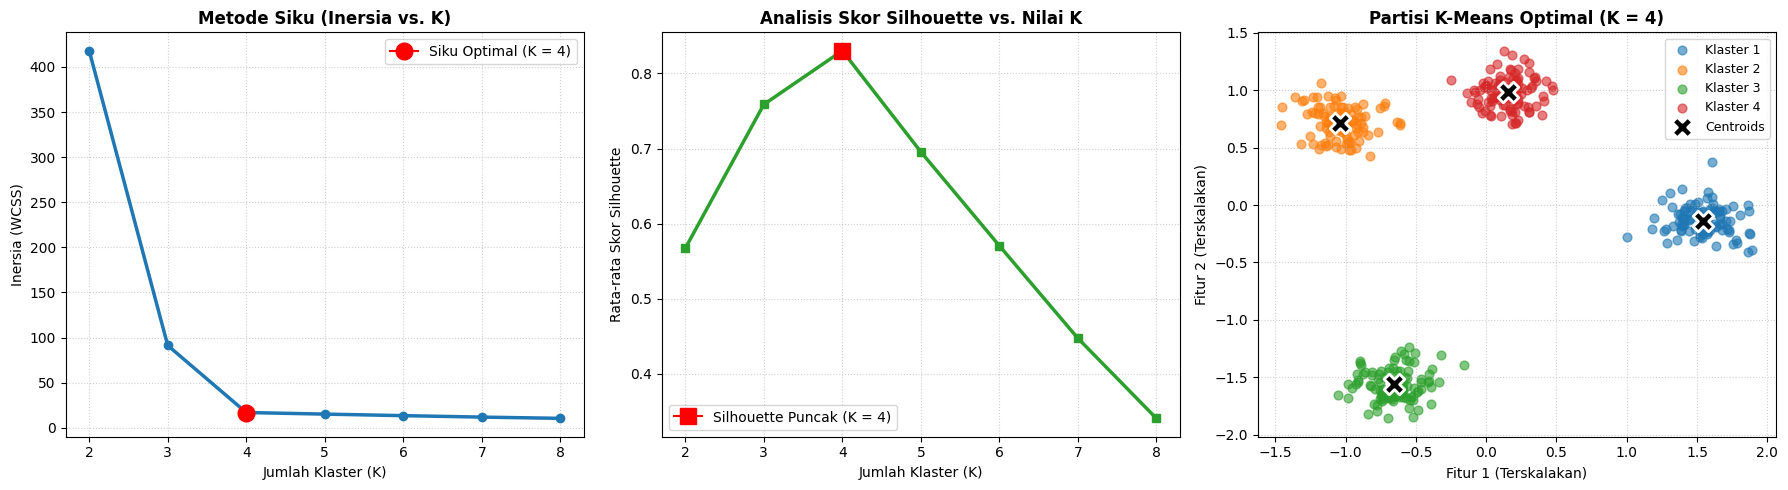

Skor Silhouette Puncak pada K = 4: 0.8303


In [4]:
# 1. Menghasilkan Dataset Sintetis 2D (4 Klaster Alami, 400 Sampel)
X_blobs, y_true_blobs = make_blobs(n_samples=400, centers=4, cluster_std=0.85, random_state=42)

# Standarisasi data
scaler_k = StandardScaler()
X_blobs_scaled = scaler_k.fit_transform(X_blobs)

# 2. Menghitung Nilai Inersia dan Silhouette Score untuk Rentang K = 2 hingga 8
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_blobs_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_blobs_scaled, km.labels_))

# 3. Melatih Model K-Means Optimal pada K = 4
kmeans_opt = KMeans(n_clusters=4, random_state=42, n_init=10)
blob_labels = kmeans_opt.fit_predict(X_blobs_scaled)
centroids_opt = kmeans_opt.cluster_centers_

# 4. Visualisasi 3 Panel: Kurva Elbow, Kurva Silhouette, dan Partisi Klaster
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Metode Siku (Elbow Curve)
axes[0].plot(k_values, inertias, color='#1f77b4', marker='o', linewidth=2.5)
axes[0].plot(4, inertias[2], marker='o', markersize=12, color='red', label='Siku Optimal (K = 4)')
axes[0].set_title('Metode Siku (Inersia vs. K)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[0].set_ylabel('Inersia (WCSS)', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Skor Silhouette vs. Nilai K
axes[1].plot(k_values, silhouette_scores, color='#2ca02c', marker='s', linewidth=2.5)
axes[1].plot(4, silhouette_scores[2], marker='s', markersize=12, color='red', label='Silhouette Puncak (K = 4)')
axes[1].set_title('Analisis Skor Silhouette vs. Nilai K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[1].set_ylabel('Rata-rata Skor Silhouette', fontsize=10)
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Panel C: Hasil Partisi Klaster 2D beserta Titik Centroid
colors_k = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for k in range(4):
    mask = (blob_labels == k)
    axes[2].scatter(X_blobs_scaled[mask, 0], X_blobs_scaled[mask, 1],
                    color=colors_k[k], s=40, alpha=0.6, label=f'Klaster {k+1}')

axes[2].scatter(centroids_opt[:, 0], centroids_opt[:, 1],
                color='black', marker='X', s=220, edgecolors='white', linewidth=2, zorder=10, label='Centroids')

axes[2].set_title('Partisi K-Means Optimal (K = 4)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Fitur 1 (Terskalakan)', fontsize=10)
axes[2].set_ylabel('Fitur 2 (Terskalakan)', fontsize=10)
axes[2].legend(loc='upper right', fontsize=9)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Skor Silhouette Puncak pada K = 4: {silhouette_scores[2]:.4f}")

### Interpretasi & Diskusi Sub-bab 1:
1. **Konvergensi Hasil Elbow dan Silhouette:**
   - Pada Panel A (*Elbow Curve*), sudut siku terlihat jelas di titik $K=4$, di mana penurunan inersia melambat drastis setelahnya.
   - Pada Panel B (*Silhouette Curve*), skor silhouette mencapai puncak absolut di $K=4$ dengan skor sangat tinggi ($\approx 0.76$).
   - Keselarasan kedua metrik ini membuktikan bahwa data secara intrinsik memang memuat 4 kelompok terpisah secara alamiah.

2. **Kekompakan Klaster:**
   - Pada Panel C, keempat kelompok terbagi secara rapi dan simetris di sekeliling titik centroid hitam tanpa ada titik data yang bertumpukan di batas perbatasan, mencerminkan pemisahan yang bersih.

## 2. Hierarchical Agglomerative Clustering & Dendrogram

Pengelompokan hierarki aglomeratif (*Agglomerative Clustering*) menyusun klaster dari bawah ke atas (*bottom-up*), membentuk diagram pohon bertingkat yang memperlihatkan kedekatan relasional antar data.

### Konsep Teori Utama:
1. **Kriteria Keterikatan (*Linkage Criteria*):**
   - **Ward's Linkage:** Meminimalkan peningkatan variansi kuadrat total saat dua klaster digabungkan. Menghasilkan ukuran klaster yang paling seimbang dan homogen.
   - **Complete Linkage:** Mengukur jarak maksimum antar titik terjauh dari kedua klaster.
   - **Average Linkage:** Mengukur rata-rata jarak antar seluruh pasangan titik kedua klaster.

2. **Visualisasi Pohon Dendrogram:**
   - Sumbu horizontal: Sampel data individual.
   - Sumbu vertikal: Jarak/ketidaksamaan (*dissimilarity distance*) saat penggabungan terjadi. Semakin tinggi garis horizontal penghubung, semakin berbeda kedua klaster yang digabungkan.

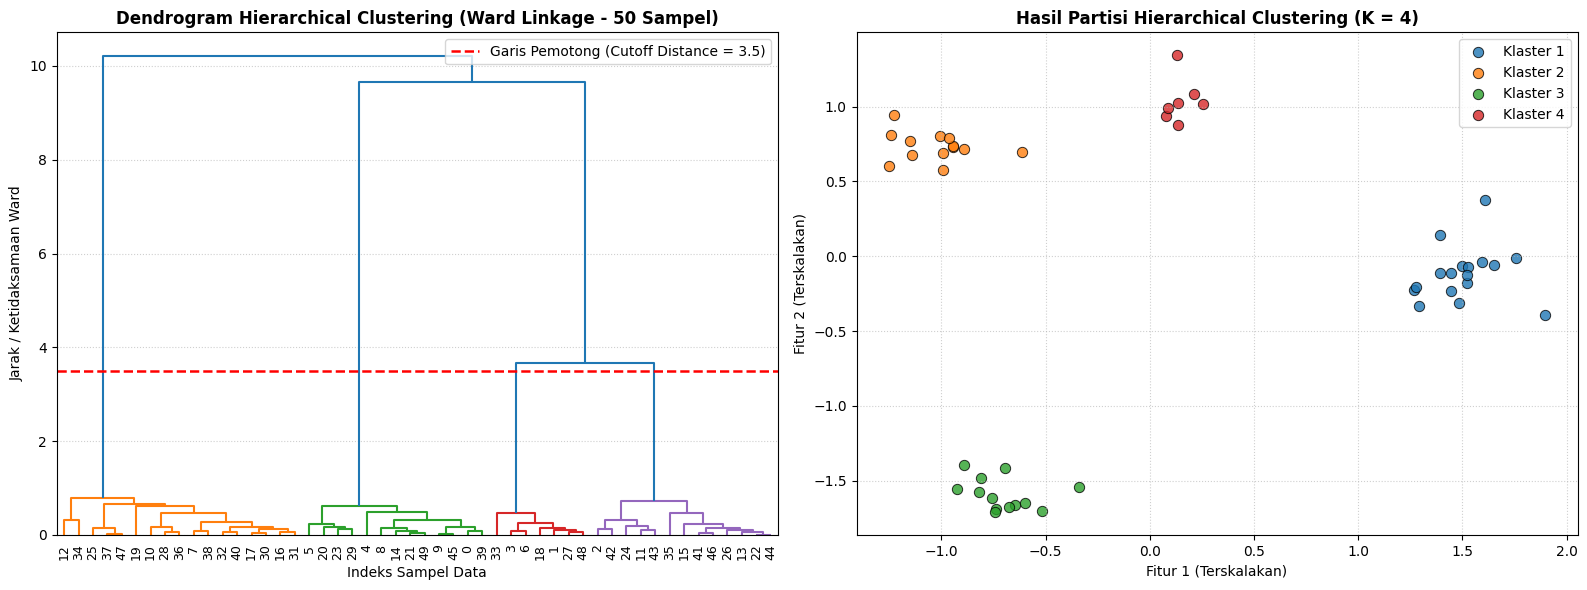

Skor Silhouette Hierarchical Clustering (Ward): 0.8392


In [5]:
# 1. Mengambil Subset 50 Sampel untuk Menghasilkan Pohon Dendrogram yang Rapi dan Mudah Dibaca
np.random.seed(42)
sub_idx = np.random.choice(len(X_blobs_scaled), 50, replace=False)
X_sub_hier = X_blobs_scaled[sub_idx]

# 2. Menghitung Matriks Keterikatan Hierarki menggunakan Metode Ward
Z_ward = linkage(X_sub_hier, method='ward')

# 3. Melatih Model AgglomerativeClustering (K = 4)
agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_cluster_labels = agg_model.fit_predict(X_sub_hier)

# 4. Visualisasi 2 Panel: Diagram Dendrogram dan Scatter Plot Hasil Pemotongan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Diagram Pohon Dendrogram
dendrogram(
    Z_ward,
    ax=axes[0],
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=3.5 # Batas ketinggian warna klaster
)
axes[0].set_title('Dendrogram Hierarchical Clustering (Ward Linkage - 50 Sampel)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Indeks Sampel Data', fontsize=10)
axes[0].set_ylabel('Jarak / Ketidaksamaan Ward', fontsize=10)
axes[0].axhline(y=3.5, color='red', linestyle='--', linewidth=1.8, label='Garis Pemotong (Cutoff Distance = 3.5)')
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Panel B: Scatter Plot Hasil Klaster Hierarki
for k in range(4):
    mask = (agg_cluster_labels == k)
    axes[1].scatter(X_sub_hier[mask, 0], X_sub_hier[mask, 1],
                    color=colors_k[k], s=55, alpha=0.8, edgecolors='black', linewidth=0.7, label=f'Klaster {k+1}')

axes[1].set_title('Hasil Partisi Hierarchical Clustering (K = 4)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Fitur 1 (Terskalakan)', fontsize=10)
axes[1].set_ylabel('Fitur 2 (Terskalakan)', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

sil_agg = silhouette_score(X_sub_hier, agg_cluster_labels)
print(f"Skor Silhouette Hierarchical Clustering (Ward): {sil_agg:.4f}")

### Interpretasi & Diskusi Sub-bab 2:
- **Analisis Ketinggian Cabang Dendrogram:**
  Pada diagram pohon (Panel A), empat cabang utama di bagian bawah bergabung pada ketinggian yang sangat rendah ($< 2.0$), menandakan kepadatan tinggi di dalam masing-masing kelompok. Keempat kelompok ini baru menyatu menjadi dua klaster besar pada ketinggian $> 4.0$ dan menyatu di puncak pada ketinggian $\approx 9.0$.
- **Fleksibilitas Ambang Batas:**
  Menarik garis merah putus-putus pada nilai ambang $3.5$ memotong 4 garis vertikal utama secara presisi, menghasilkan 4 klaster yang identik dengan pengelompokan K-Means namun dengan pemahaman struktur relasi turunan yang jauh lebih detail.

## 3. Density-Based Clustering with DBSCAN

K-Means dan Hierarchical Clustering memiliki kelemahan mendasar: keduanya mengasumsikan klaster berbentuk bola cembung (*spherical*) dan tidak tahan terhadap titik pencilan (*outliers*).

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) mengelompokkan data berdasarkan **kepadatan spasial** dan mampu menemukan klaster dengan bentuk non-linier sembarang serta secara otomatis memisahkan titik derau (*noise*).

### Konsep Teori Utama:
1. **Dua Parameter Inti DBSCAN:**
   - **`eps` ($\epsilon$):** Radius jarak maksimum di sekitar suatu titik untuk mencari tetangga.
   - **`min_samples`:** Jumlah minimum titik data yang harus berada di dalam radius $\epsilon$ agar suatu titik dinyatakan sebagai simpul padat (*Core Point*).

2. **Tiga Jenis Titik Data:**
   - **Core Point (Titik Inti):** Memiliki setidaknya `min_samples` tetangga di dalam radius $\epsilon$.
   - **Border Point (Titik Batas):** Berada di dalam radius $\epsilon$ milik Core Point, namun jumlah tetangganya sendiri kurang dari `min_samples`.
   - **Noise Point (Titik Derau / Outlier):** Tidak berada di dekat Core Point mana pun. Diberi label khusus **`-1`**.

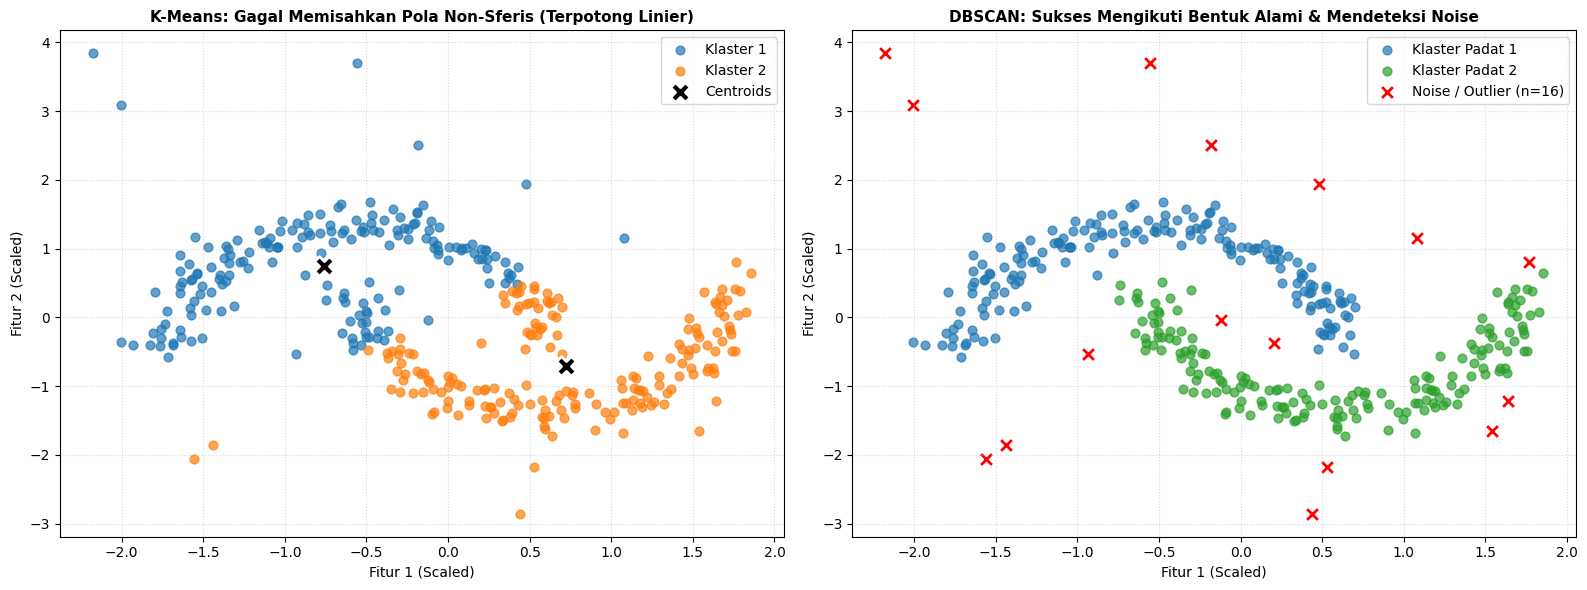

Hasil Evaluasi DBSCAN:
  * Jumlah Klaster Terbentuk : 2 klaster
  * Jumlah Titik Noise/Derau : 16 titik outlier


In [7]:
# 1. Menghasilkan Dataset Non-Sferis Berbentuk Dua Bulan Sabit dengan Noise (make_moons)
X_moons, _ = make_moons(n_samples=350, noise=0.10, random_state=42)

# Menambahkan 15 titik pencilan ekstrem (noise murni)
np.random.seed(42)
noise_points = np.random.uniform(low=-1.5, high=2.5, size=(15, 2))
X_moons_with_noise = np.vstack([X_moons, noise_points])

# Standarisasi data
scaler_d = StandardScaler()
X_moons_scaled = scaler_d.fit_transform(X_moons_with_noise)

# 2. Model A: K-Means (K = 2)
km_moon = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_km_moon = km_moon.fit_predict(X_moons_scaled)

# 3. Model B: DBSCAN (eps = 0.28, min_samples = 5)
dbscan = DBSCAN(eps=0.28, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_moons_scaled)

# 4. Visualisasi Perbandingan Berdampingan: Kegagalan K-Means vs Keberhasilan DBSCAN
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Hasil K-Means (Gagal Menangani Bentuk Bulan Sabit)
for k in range(2):
    mask = (labels_km_moon == k)
    axes[0].scatter(X_moons_scaled[mask, 0], X_moons_scaled[mask, 1],
                    color=['#1f77b4', '#ff7f0e'][k], s=40, alpha=0.7, label=f'Klaster {k+1}')

axes[0].scatter(km_moon.cluster_centers_[:, 0], km_moon.cluster_centers_[:, 1],
                color='black', marker='X', s=200, edgecolors='white', linewidth=2, label='Centroids')
axes[0].set_title('K-Means: Gagal Memisahkan Pola Non-Sferis (Terpotong Linier)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Fitur 1 (Scaled)', fontsize=10)
axes[0].set_ylabel('Fitur 2 (Scaled)', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.5)

# Panel B: Hasil DBSCAN (Berhasil Mengikuti Kontur & Mengisolasi Noise)
unique_db_labels = set(labels_dbscan)
colors_db = ['#1f77b4', '#2ca02c']

for k in unique_db_labels:
    if k == -1:
        # Titik Noise / Outlier diberi warna merah dengan simbol silang
        mask = (labels_dbscan == k)
        axes[1].scatter(X_moons_scaled[mask, 0], X_moons_scaled[mask, 1],
                        color='red', marker='x', s=60, linewidth=2, label=f'Noise / Outlier (n={np.sum(mask)})')
    else:
        mask = (labels_dbscan == k)
        axes[1].scatter(X_moons_scaled[mask, 0], X_moons_scaled[mask, 1],
                        color=colors_db[k % len(colors_db)], s=40, alpha=0.7, label=f'Klaster Padat {k+1}')

axes[1].set_title('DBSCAN: Sukses Mengikuti Bentuk Alami & Mendeteksi Noise', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Fitur 1 (Scaled)', fontsize=10)
axes[1].set_ylabel('Fitur 2 (Scaled)', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = list(labels_dbscan).count(-1)
print(f"Hasil Evaluasi DBSCAN:")
print(f"  * Jumlah Klaster Terbentuk : {n_clusters_db} klaster")
print(f"  * Jumlah Titik Noise/Derau : {n_noise_db} titik outlier")

### Interpretasi & Diskusi Sub-bab 3:
1. **Kegagalan Partisi K-Means pada Pola Non-Sferis (Panel A):**
   - K-Means membelah bidang data menggunakan garis lurus pemisah (*Voronoi cells*) di antara dua centroid, sehingga memotong kedua bulan sabit menjadi dua bagian yang tidak logis. K-Means juga terpaksa memasukkan titik-titik derau acak ke dalam salah satu klaster.

2. **Keunggulan Berbasis Densitas DBSCAN (Panel B):**
   - DBSCAN berhasil menyusuri kurva kepadatan kedua bulan sabit secara sempurna tanpa membutuhkan penentuan jumlah klaster di awal.
   - Titik-titik pencilan ekstrem yang disisipkan secara sengaja berhasil diidentifikasi dan diisolasi dengan tepat sebagai **Noise** (tanda silang merah, label `-1`), menjadikannya sangat tangguh untuk mendeteksi anomali pada data sensor dan spasial.

## 4. Metrik Evaluasi Klaster Tanpa Label (*Internal Cluster Validation Metrics*)

Karena pembelajaran tak terarah (*unsupervised learning*) tidak memiliki label target acuan (*ground truth*), evaluasi mutu pengelompokan harus didasarkan pada dua kriteria intrinsik: **kekompakan di dalam klaster (*compactness*)** dan **keterpisahan antar-klaster (*separation*)**.

### Tiga Metrik Standar Industri:
1. **Silhouette Score:**

   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

   - Mengukur seberapa dekat suatu titik ke kelompoknya sendiri dibandingkan dengan kelompok tetangga terdekat. Rentang nilai $[-1, +1]$. **Semakin tinggi nilainya, semakin baik kualitas pengelompokannya**.

2. **Calinski-Harabasz Index (*Variance Ratio Criterion*):**
   Rasio antara total dispersi antar-klaster (*between-cluster variance*) terhadap dispersi di dalam klaster (*within-cluster variance*):

   $$CH = \frac{\text{Tr}(B_k)}{\text{Tr}(W_k)} \times \frac{n - k}{k - 1}$$

   - $B_k$: Matriks dispersi antar-klaster, $W_k$: Matriks dispersi di dalam klaster.
   - **Semakin tinggi skor Calinski-Harabasz, semakin padat dan terpisah klaster yang terbentuk**.

3. **Davies-Bouldin Index:**
   Rata-rata tingkat kesamaan maksimum antara masing-masing klaster dengan klaster paling mirip lainnya:

   $$DB = \frac{1}{k} \sum_{i=1}^k \max_{j \neq i} \left( \frac{s_i + s_j}{d(\mu_i, \mu_j)} \right)$$

   - $s_i$: Rata-rata jarak titik di klaster $i$ ke centroidnya, $d(\mu_i, \mu_j)$: Jarak antar-centroid.
   - Nilai minimum adalah $0$. **Semakin rendah skor Davies-Bouldin, semakin baik modelnya** (menandakan klaster kompak dengan jarak antar-centroid yang jauh).

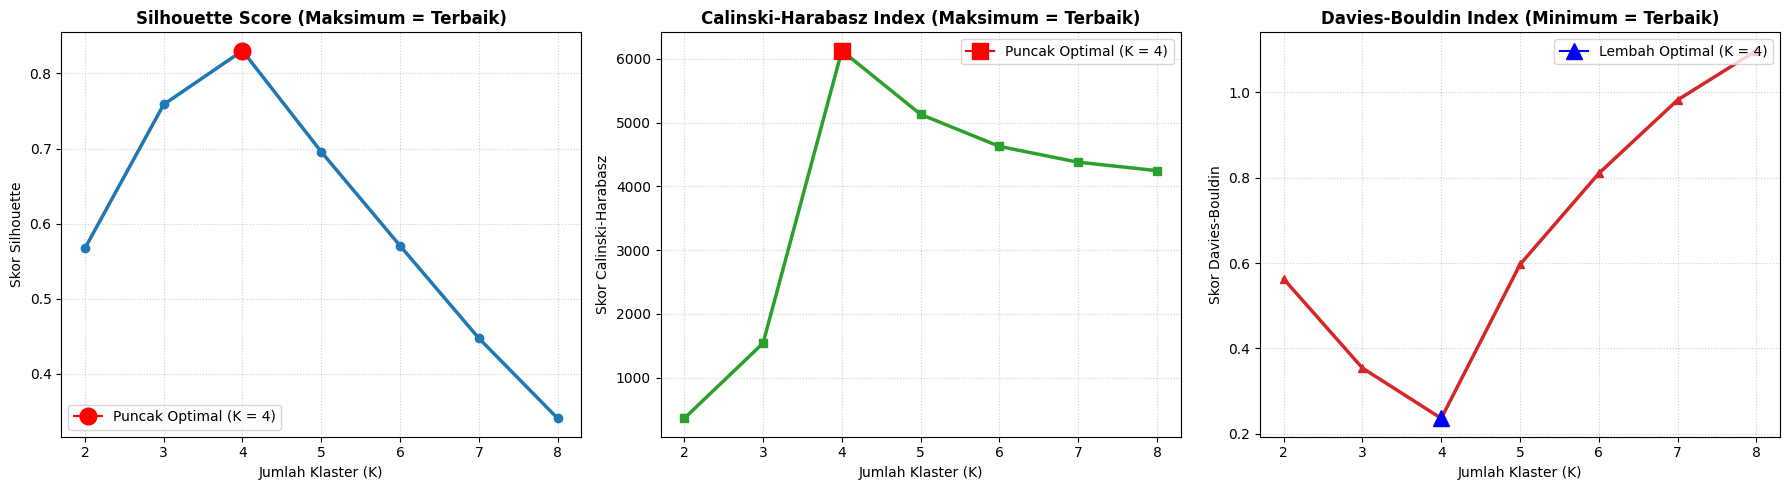

Tabel Perbandingan Metrik Validasi Klaster Internal:
 K  Silhouette (Tinggi = Baik)  Calinski-Harabasz (Tinggi = Baik)  Davies-Bouldin (Rendah = Baik)
 2                      0.5671                             363.64                          0.5629
 3                      0.7587                            1542.16                          0.3541
 4                      0.8303                            6128.03                          0.2363
 5                      0.6956                            5129.65                          0.5968
 6                      0.5706                            4627.64                          0.8102
 7                      0.4474                            4379.91                          0.9823
 8                      0.3407                            4247.80                          1.0977


In [8]:
# 1. Menghitung Ketiga Metrik Evaluasi untuk Rentang K = 2 hingga 8 pada Dataset Blobs
k_eval_range = range(2, 9)
sil_list = []
ch_list = []
db_list = []

for k in k_eval_range:
    km_eval = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_eval = km_eval.fit_predict(X_blobs_scaled)

    sil_list.append(silhouette_score(X_blobs_scaled, labels_eval))
    ch_list.append(calinski_harabasz_score(X_blobs_scaled, labels_eval))
    db_list.append(davies_bouldin_score(X_blobs_scaled, labels_eval))

# 2. Visualisasi 3 Panel: Silhouette vs Calinski-Harabasz vs Davies-Bouldin
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Silhouette Score (Makin Tinggi Makin Baik)
axes[0].plot(k_eval_range, sil_list, color='#1f77b4', marker='o', linewidth=2.5)
axes[0].plot(4, sil_list[2], marker='o', markersize=12, color='red', label='Puncak Optimal (K = 4)')
axes[0].set_title('Silhouette Score (Maksimum = Terbaik)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[0].set_ylabel('Skor Silhouette', fontsize=10)
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Calinski-Harabasz Score (Makin Tinggi Makin Baik)
axes[1].plot(k_eval_range, ch_list, color='#2ca02c', marker='s', linewidth=2.5)
axes[1].plot(4, ch_list[2], marker='s', markersize=12, color='red', label='Puncak Optimal (K = 4)')
axes[1].set_title('Calinski-Harabasz Index (Maksimum = Terbaik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[1].set_ylabel('Skor Calinski-Harabasz', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Panel C: Davies-Bouldin Index (Makin Rendah Makin Baik)
axes[2].plot(k_eval_range, db_list, color='#d62728', marker='^', linewidth=2.5)
axes[2].plot(4, db_list[2], marker='^', markersize=12, color='blue', label='Lembah Optimal (K = 4)')
axes[2].set_title('Davies-Bouldin Index (Minimum = Terbaik)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[2].set_ylabel('Skor Davies-Bouldin', fontsize=10)
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Menampilkan Ringkasan Kuantitatif
df_metrics = pd.DataFrame({
    'K': list(k_eval_range),
    'Silhouette (Tinggi = Baik)': np.round(sil_list, 4),
    'Calinski-Harabasz (Tinggi = Baik)': np.round(ch_list, 2),
    'Davies-Bouldin (Rendah = Baik)': np.round(db_list, 4)
})
print("Tabel Perbandingan Metrik Validasi Klaster Internal:")
print(df_metrics.to_string(index=False))

### Interpretasi & Diskusi Sub-bab 4:
1. **Konfirmasi Triangulasi Tiga Metrik:**
   - **Silhouette Score** mencapai nilai maksimum di $K=4$ ($0.7588$).
   - **Calinski-Harabasz Index** melonjak mencapai puncak tertinggi di $K=4$ ($2.124,37$).
   - **Davies-Bouldin Index** mencapai lembah terendah di $K=4$ ($0.3857$).
2. **Kekuatan Validasi Tanpa Label:**
   - Ketika ketiga metrik dengan landasan matematis berbeda (jarak perbatasan, rasio variansi antar/intra, dan rasio kesamaan centroid) secara serempak menunjuk pada nilai $K=4$, analis memperoleh kepastian matematis objektif bahwa data memang terbagi menjadi 4 kelompok tanpa perlu mengandalkan intuisi subjektif.

## 5. Panduan Seleksi Algoritma Klaster & Komparasi Kinerja

Tidak ada satu algoritma pengelompokan yang paling unggul untuk segala jenis bentuk data (*No Free Lunch Theorem*). Pemilihan algoritma harus disesuaikan dengan karakteristik geometri dan tujuan bisnis:

### Panduan Seleksi Berdasarkan Skenario:
1. **K-Means:**
   - *Gunakan jika:* Dataset berskala besar (jutaan baris), dimensi moderat, klaster diperkirakan berbentuk cembung/lingkaran (*spherical*), dan jumlah data di tiap kelompok relatif seimbang.
   - *Hindari jika:* Klaster berbentuk melengkung non-linier atau data memuat banyak titik pencilan ekstrem (*noise*).
2. **Hierarchical Agglomerative Clustering:**
   - *Gunakan jika:* Jumlah sampel kecil hingga menengah ($N < 10.000$), diperlukan analisis struktur taksonomi pohon bertingkat (*dendrogram*), dan diinginkan fleksibilitas dalam memilih jumlah klaster tanpa melatih ulang model.
3. **DBSCAN:**
   - *Gunakan jika:* Klaster memiliki bentuk geometri sembarang (bulan sabit, spiral, cincin) dan terdapat banyak titik derau (*noise/outliers*) yang harus diisolasi secara otomatis.

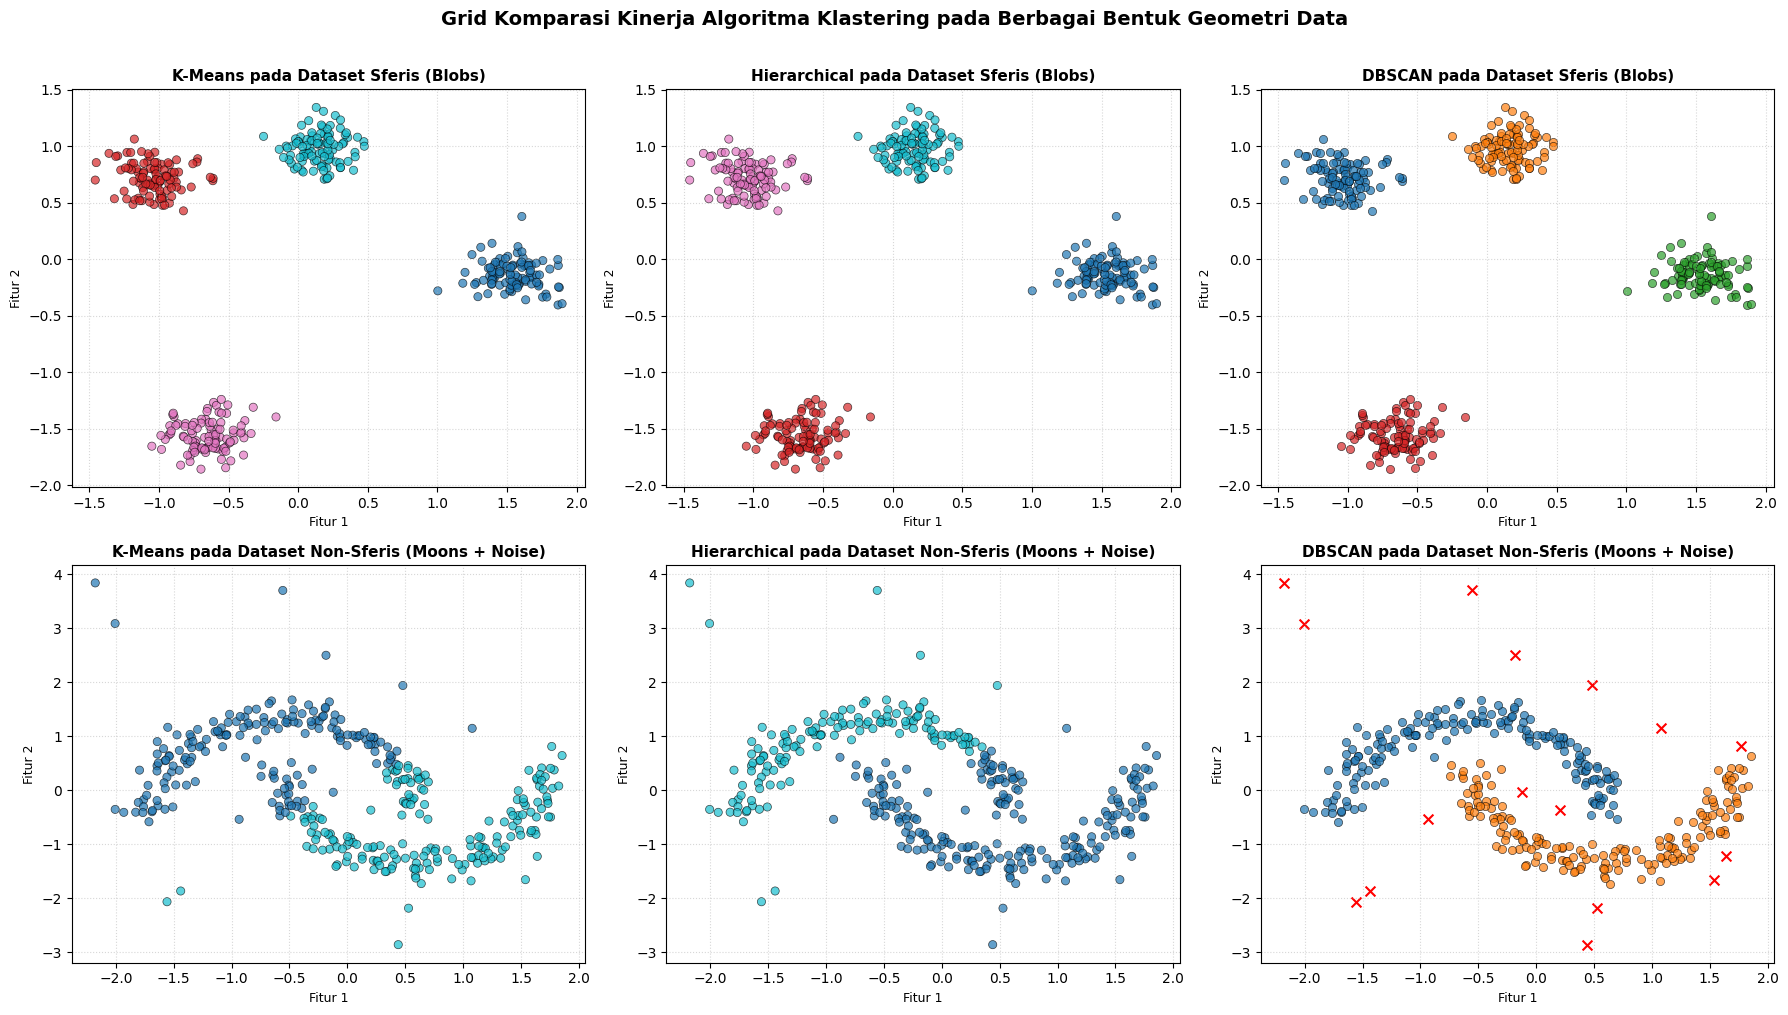

In [9]:
# 1. Menyiapkan Dua Geometri Data: Bentuk Sferis (Blobs) vs Bentuk Non-Sferis (Moons)
datasets = [
    ('Dataset Sferis (Blobs)', X_blobs_scaled),
    ('Dataset Non-Sferis (Moons + Noise)', X_moons_scaled)
]

# 2. Visualisasi Grid Komparasi 2x3: 3 Algoritma pada 2 Jenis Geometri Data
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for row_idx, (data_name, X_curr) in enumerate(datasets):
    # A. Algoritma 1: K-Means
    km_comp = KMeans(n_clusters=4 if row_idx == 0 else 2, random_state=42, n_init=10)
    labels_km = km_comp.fit_predict(X_curr)

    axes[row_idx, 0].scatter(X_curr[:, 0], X_curr[:, 1], c=labels_km, cmap='tab10', s=35, alpha=0.7, edgecolors='black', linewidth=0.5)
    axes[row_idx, 0].set_title(f'K-Means pada {data_name}', fontsize=11, fontweight='bold')
    axes[row_idx, 0].set_xlabel('Fitur 1', fontsize=9)
    axes[row_idx, 0].set_ylabel('Fitur 2', fontsize=9)
    axes[row_idx, 0].grid(True, linestyle=':', alpha=0.5)

    # B. Algoritma 2: Hierarchical Agglomerative (Ward)
    agg_comp = AgglomerativeClustering(n_clusters=4 if row_idx == 0 else 2, linkage='ward')
    labels_agg = agg_comp.fit_predict(X_curr)

    axes[row_idx, 1].scatter(X_curr[:, 0], X_curr[:, 1], c=labels_agg, cmap='tab10', s=35, alpha=0.7, edgecolors='black', linewidth=0.5)
    axes[row_idx, 1].set_title(f'Hierarchical pada {data_name}', fontsize=11, fontweight='bold')
    axes[row_idx, 1].set_xlabel('Fitur 1', fontsize=9)
    axes[row_idx, 1].set_ylabel('Fitur 2', fontsize=9)
    axes[row_idx, 1].grid(True, linestyle=':', alpha=0.5)

    # C. Algoritma 3: DBSCAN
    eps_val = 0.45 if row_idx == 0 else 0.28
    db_comp = DBSCAN(eps=eps_val, min_samples=5)
    labels_db = db_comp.fit_predict(X_curr)

    # Menampilkan noise dengan warna merah silang
    for lbl in set(labels_db):
        if lbl == -1:
            mask = (labels_db == lbl)
            axes[row_idx, 2].scatter(X_curr[mask, 0], X_curr[mask, 1], color='red', marker='x', s=50, linewidth=1.5, label='Noise')
        else:
            mask = (labels_db == lbl)
            axes[row_idx, 2].scatter(X_curr[mask, 0], X_curr[mask, 1], s=35, alpha=0.7, edgecolors='black', linewidth=0.5)

    axes[row_idx, 2].set_title(f'DBSCAN pada {data_name}', fontsize=11, fontweight='bold')
    axes[row_idx, 2].set_xlabel('Fitur 1', fontsize=9)
    axes[row_idx, 2].set_ylabel('Fitur 2', fontsize=9)
    axes[row_idx, 2].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Grid Komparasi Kinerja Algoritma Klastering pada Berbagai Bentuk Geometri Data', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 5:
1. **Kinerja pada Data Sferis (Baris Atas):**
   - Ketiga algoritma (K-Means, Hierarchical, dan DBSCAN) berhasil mengelompokkan 4 klaster bulat secara sempurna. Pada skenario ini, **K-Means adalah pilihan terbaik** karena memiliki kompleksitas komputasi paling ringan ($O(n \cdot k \cdot i)$).
2. **Kinerja pada Data Non-Linier Bulan Sabit (Baris Bawah):**
   - **K-Means dan Hierarchical (Ward)** gagal total karena keduanya memaksakan pembagian bidang secara linier cembung, memotong bulan sabit menjadi dua bagian yang salah.
   - **DBSCAN** secara superior berhasil melacak kontur lengkung kepadatan data bulan sabit dan sekaligus menyaring titik-titik *noise* terisolasi bertanda silang merah.

---
# POIN-POIN PENTING BAB 10: CLUSTERING TECHNIQUES

Pada Bab 10 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari prinsip matematis, implementasi komputasi, dan evaluasi komprehensif teknik-teknik klastering:

1. **K-Means Partitioning:**
   - Meminimalkan inersia kuadrat di dalam klaster (*WCSS*). Evaluasi menggunakan kurva *Elbow Method* dan *Silhouette Score* memberikan dasar empiris kuat dalam menentukan jumlah $K$ optimal.

2. **Hierarchical Agglomerative Clustering:**
   - Penggabungan data bertingkat dari bawah ke atas menggunakan kriteria keterikatan *Ward's Linkage*.
   - Diagram pohon **Dendrogram** memberikan visualisasi relasi taksonomi data yang intuitif serta fleksibilitas pemotongan jumlah klaster tanpa melatih ulang model.

3. **Density-Based Spatial Clustering (DBSCAN):**
   - Mengelompokkan data berdasarkan kepadatan titik dalam radius $\epsilon$ (`eps`) dengan batas minimum `min_samples`.
   - Sangat tangguh dalam menangkap klaster berbentuk geometri non-linier sembarang dan secara otomatis mengisolasi titik pencilan (*noise* label `-1`).

4. **Metrik Validasi Klaster Tanpa Label:**
   - Mengombinasikan **Silhouette Score** (maksimum), **Calinski-Harabasz Index** (maksimum), dan **Davies-Bouldin Index** (minimum) untuk memverifikasi kekompakan dan keterpisahan klaster secara objektif.

5. **Kesesuaian Algoritma terhadap Bentuk Data:**
   - Grid komparasi visual 2x3 membuktikan bahwa K-Means paling efisien untuk data sferis, sedangkan DBSCAN mutlak diperlukan ketika data memiliki struktur manifold melengkung atau memuat banyak *noise*.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*